In [16]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


PROJECT_ROOT = Path.cwd().parent

REPRESENTATIONS_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "representations"
)

FIGURES_DIR = (
    PROJECT_ROOT
    / "reports"
    / "figures"
)

TABLES_DIR = (
    PROJECT_ROOT
    / "reports"
    / "tables"
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

Ucitavamo izdvojene reprezentacije.

In [17]:
representations_path = (
    REPRESENTATIONS_DIR
    / "optimized_mlp_test_representations.npz"
)

layer_names = [
    "input",
    "hidden_1",
    "hidden_2",
    "bottleneck"
]

with np.load(representations_path) as saved_data:

    representations = {
        layer_name: saved_data[layer_name]
        for layer_name in layer_names
    }

In [18]:
for layer_name, values in representations.items():

    print(
        f"{layer_name}: "
        f"shape={values.shape}, "
        f"dtype={values.dtype}"
    )

input: shape=(19868, 168), dtype=float32
hidden_1: shape=(19868, 256), dtype=float32
hidden_2: shape=(19868, 128), dtype=float32
bottleneck: shape=(19868, 16), dtype=float32


Provera da svi slojevi sadrze iste primere.

In [19]:
number_of_examples = {
    values.shape[0]
    for values in representations.values()
}

if len(number_of_examples) != 1:
    raise ValueError(
        "Reprezentacije nemaju isti broj primera."
    )

print(
    "Broj primera u svim reprezentacijama:",
    number_of_examples.pop()
)

Broj primera u svim reprezentacijama: 19868


Centered Kernel Alignment poredi reprezentacije dva sloja, ispituje da li dva prostora na slican nacin organizuju iste primere.<br>
Npr, ako su dva zapisa medjusobno slicna u 1. sloju, CKA proverava da li su medjusobno slicna i u 2. zato mozemo porediti matrice razlicitih broja kolona, ali istog broja redova.

Pre racunanja CKA, svakoj koloni oduzimamo njenu prosecnu vrednost, na taj nacin centriramo vrednosti, tako da struktura ostaje ista i rezultat ne zavisi od toga ako jedan sloj prozivodi vece prosecne vrednosti od drugog.

In [20]:
def center_representation(values):

    values = np.asarray(
        values,
        dtype=np.float64
    )

    column_means = values.mean(
        axis=0,
        keepdims=True
    )

    centered_values = (
        values - column_means
    )

    return centered_values

In [21]:
centered_representations = {
    layer_name: center_representation(values)
    for layer_name, values
    in representations.items()
}

Provera, rezultati bi trebalo da budu blizu 0.

In [22]:
for layer_name, values in (
    centered_representations.items()
):

    print(
        layer_name,
        np.abs(
            values.mean(axis=0)
        ).max()
    )

input 2.2386601218734543e-15
hidden_1 1.4471344731891788e-15
hidden_2 3.0132178210194056e-15
bottleneck 1.2736048486335637e-15


## Funkcija za linearni CKA.<br>
CKA daje jedan broj koji pokazuje koliko su dve reprezentacije slicne po svojoj unutrasnjoj strukturi.<br>
Racunamo CKA izmedju svakog para prostora, nasa hipoteza je da je sloj blizi bottleneck-u slican njemu.<br>
cross_similarity svaka celija predstavlja koliko se jedna dimenzija iz prvog prostora i jedna dimenzija iz drugog prostora zajedno menjaju.<br>
self_similarity pokazuje odnos izmedju dva neurona istog sloja kroz sve primere.<br>
numerator i denominator se koriste za racunanje Frobenijusove norme matrice (koren zbira kvadrata elemenata matrice).<br>
kada se koristi centered_y.T @ centered_y, onih 5 mrtvih neurona ne uticu na CKA rezultat jer samo dodaju 5 nultih kolona, kada se racuna norma, te dodatne nule ne menjaju vrednost.
numerator predstavlja ukupnu jacinu povezanosti izmedju dimenzija dve reprezentacije.<br>
denominator sluzi za normalizaciju vrednosti, bez imenioca, sloj sa vecim aktivacijama bi dao veci rezultat.<br>

In [23]:
def linear_cka(
    centered_x,
    centered_y
):

    cross_similarity = (
        centered_x.T
        @ centered_y
    )

    self_similarity_x = (
        centered_x.T
        @ centered_x
    )

    self_similarity_y = (
        centered_y.T
        @ centered_y
    )

    numerator = (
        np.linalg.norm(
            cross_similarity,
            ord="fro"
        )
        ** 2
    )

    denominator = (
        np.linalg.norm(
            self_similarity_x,
            ord="fro"
        )
        *
        np.linalg.norm(
            self_similarity_y,
            ord="fro"
        )
    )

    if np.isclose(denominator, 0):
        raise ValueError(
            "CKA nije moguće izračunati "
            "za reprezentaciju bez varijacije."
        )

    cka_value = numerator / denominator

    return float(
        np.clip(
            cka_value,
            0.0,
            1.0
        )
    )

Uporedjujemo svaki sloj sa svakim.

In [24]:
number_of_layers = len(layer_names)

cka_matrix = np.zeros(
    (
        number_of_layers,
        number_of_layers
    )
)

for i, first_layer in enumerate(layer_names):

    for j, second_layer in enumerate(
        layer_names
    ):

        cka_matrix[i, j] = linear_cka(
            centered_representations[
                first_layer
            ],
            centered_representations[
                second_layer
            ]
        )

Provera.

In [25]:
print(
    "Dijagonala:",
    np.diag(cka_matrix)
)

print(
    "Matrica je simetrična:",
    np.allclose(
        cka_matrix,
        cka_matrix.T
    )
)

print(
    "Sve vrednosti su konačne:",
    np.isfinite(cka_matrix).all()
)

Dijagonala: [1. 1. 1. 1.]
Matrica je simetrična: True
Sve vrednosti su konačne: True


Rezultate pretvaramo u tabelu.

In [26]:
cka_df = pd.DataFrame(
    cka_matrix,
    index=layer_names,
    columns=layer_names
)

cka_df.round(4)

,input,hidden_1,hidden_2,bottleneck
input,1.0000,0.4594,0.3648,0.3545
hidden_1,0.4594,1.0000,0.9432,0.9319
hidden_2,0.3648,0.9432,1.0000,0.9956
bottleneck,0.3545,0.9319,0.9956,1.0000


In [27]:
cka_table_path = (
    TABLES_DIR
    / "linear_cka_layer_similarity.csv"
)

cka_df.to_csv(
    cka_table_path,
    index=True
)

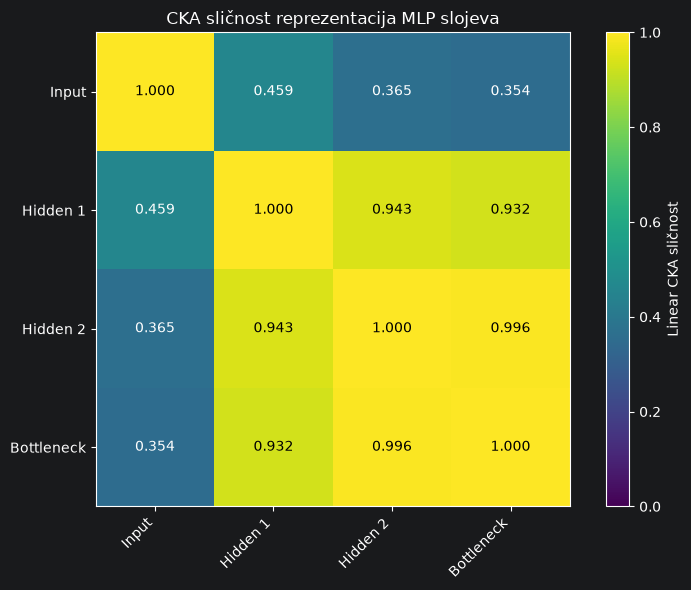

In [28]:
layer_labels = [
    "Input",
    "Hidden 1",
    "Hidden 2",
    "Bottleneck"
]

figure_path = (
    FIGURES_DIR
    / "linear_cka_layer_similarity.png"
)

fig, ax = plt.subplots(
    figsize=(8, 6)
)

image = ax.imshow(
    cka_matrix,
    vmin=0,
    vmax=1
)

ax.set_xticks(
    np.arange(number_of_layers)
)

ax.set_yticks(
    np.arange(number_of_layers)
)

ax.set_xticklabels(
    layer_labels,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(
    layer_labels
)

for row_index in range(number_of_layers):

    for column_index in range(
        number_of_layers
    ):

        value = cka_matrix[
            row_index,
            column_index
        ]

        text_color = (
            "white"
            if value < 0.5
            else "black"
        )

        ax.text(
            column_index,
            row_index,
            f"{value:.3f}",
            ha="center",
            va="center",
            color=text_color
        )

colorbar = fig.colorbar(
    image,
    ax=ax
)

colorbar.set_label(
    "Linear CKA sličnost"
)

ax.set_title(
    "CKA sličnost reprezentacija MLP slojeva"
)

plt.tight_layout()

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Direktna provera hipoteze o priblizavanju bottleneck-u.

In [29]:
bottleneck_similarities = cka_df.loc[
    [
        "input",
        "hidden_1",
        "hidden_2"
    ],
    "bottleneck"
]

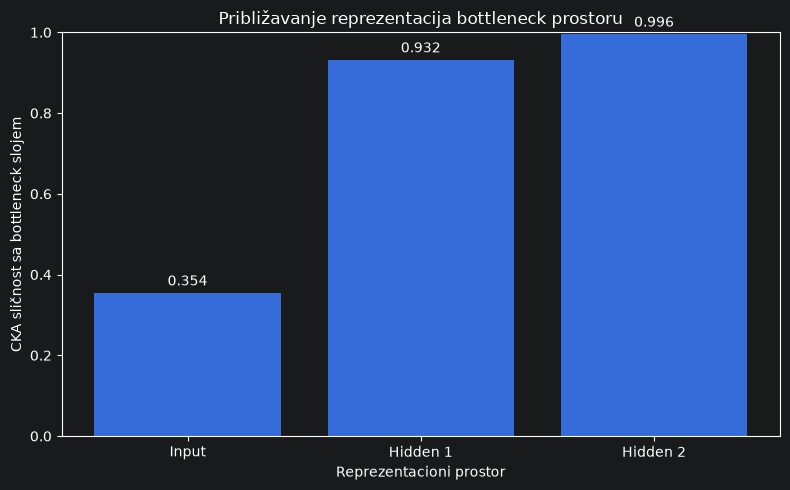

In [30]:
figure_path = (
    FIGURES_DIR
    / "cka_similarity_to_bottleneck.png"
)

plt.figure(
    figsize=(8, 5)
)

bars = plt.bar(
    [
        "Input",
        "Hidden 1",
        "Hidden 2"
    ],
    bottleneck_similarities.values
)

plt.ylim(0, 1)

plt.xlabel(
    "Reprezentacioni prostor"
)

plt.ylabel(
    "CKA sličnost sa bottleneck slojem"
)

plt.title(
    "Približavanje reprezentacija "
    "bottleneck prostoru"
)

plt.bar_label(
    bars,
    fmt="%.3f",
    padding=3
)

plt.tight_layout()

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Rezultati podrzavaju hipotezu o postepenom priblizavanju reprezentaciji bottleneck prostoru.<br>
Vrednosti na dijagonali su 1 jer se svaki sloj poredi sa samim sobom, matrica je simetricna sto potvrdjuje da je racunanje dosledno.<br>
Slicnost izmedju ulaznog prostora u odnosu na slojeve se smanjuje sto pokazuje da mreza tokom prolaska kroz slojeve menja nacin na koji organizuje podatke.<br>
Bottleneck prostor nije samo smanjena kopija pretprocesiranih ulaznih podataka, vec naucena transformacija.<br>
Slicnosti izmedju slojeva su visoke, sto znaci da slojevi slicno organizuju podatke.<br>
Najveca slicnost je izmedju drugog i bottleneck sloja. 0,996, slojevi gotovo isto organizuju podatke, iako se broj dimenzija smanjuje sa 128 na 16, dakle struktura u velikom prostoru se moze predstaviti znatno kompaktnije.